# 02 — Prétraitement : choix du filtre, normalisation photométrique, alignement
Chaîne étudiée (module `src/preprocessing.py`) :

`gris + 256×256 (INTER_AREA)` → `filtre de débruitage` → `normalisation photométrique` → `alignement sur l'image de référence`

Trois questions, trois expériences :
- **A.** Quel filtre de débruitage ? → PSNR / SSIM (Ch. 3)
- **B.** Quelle normalisation photométrique ? → le décalage d'éclairage train/test observé au notebook 01 doit disparaître
- **C.** Quelle méthode d'alignement ? → ORB + RANSAC (Ch. 1, Ch. 2) vs centroïde + recherche d'angle (Ch. 2, Ch. 3)

In [1]:
import sys, time
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
import numpy as np, pandas as pd, cv2
import matplotlib.pyplot as plt
from skimage.metrics import peak_signal_noise_ratio as psnr, structural_similarity as ssim
from sklearn.metrics import roc_auc_score
from src.data_loader import load_config, get_splits, load_image, load_mask
from src.preprocessing import (to_gray_resized, denoise, normalize_photometric, Aligner, Preprocessor, ncc, otsu_mask)

cfg = load_config(ROOT / "config.yaml"); CATS = cfg["data"]["categories"]; S = cfg["preprocessing"]["image_size"]
OUT = ROOT / "results" / "02_pretraitement"; OUT.mkdir(parents=True, exist_ok=True)
splits = {c: get_splits(c, cfg) for c in CATS}
# images en niveaux de gris 256x256, calculées une seule fois
G = {c: {k: [to_gray_resized(load_image(x.path), S) for x in v] for k, v in splits[c].items()} for c in CATS}
Y = {c: np.array([x.label for x in splits[c]["test"]]) for c in CATS}
print({c: {k: len(v) for k, v in G[c].items()} for c in CATS})
print("Configuration :", cfg["preprocessing"])

{'bottle': {'train': 167, 'val': 42, 'test': 83}, 'hazelnut': {'train': 313, 'val': 78, 'test': 110}, 'carpet': {'train': 224, 'val': 56, 'test': 117}}
Configuration : {'image_size': 256, 'grayscale': True, 'denoise': 'median', 'median_ksize': 3, 'normalize': 'minmax', 'normalize_per_category': {'bottle': 'none', 'hazelnut': 'none', 'carpet': 'localnorm'}, 'denoise_per_category': {'carpet': 'none'}, 'clahe_clip': 2.0, 'align': True, 'align_method': 'rotsearch', 'no_align_categories': ['carpet', 'grid', 'leather', 'tile', 'wood'], 'otsu_mask': False}


## A. Choix du filtre de débruitage (Ch. 3, PSNR / SSIM)
On part d'images saines (validation), on ajoute un bruit **connu**, on filtre, et on compare à l'image d'origine :
- bruit **poivre et sel** (5 % des pixels, impulsionnel) ;
- bruit **gaussien** additif (σ = 15) ;
- **sans bruit** : mesure de la perte de détails causée par le filtre lui-même (un bon filtre ne doit pas abîmer une image propre, car les défauts sont des détails fins).

PSNR = 10·log10(255²/MSE) (dB, plus grand = mieux) ; SSIM ∈ [0, 1] (1 = identique).

In [2]:
rng = np.random.default_rng(0)
def salt_pepper(img, p=0.05):
    out = img.copy(); r = rng.random(img.shape)
    out[r < p / 2] = 0; out[r > 1 - p / 2] = 255; return out
def gaussian_noise(img, sigma=15):
    return np.clip(img.astype(np.float32) + rng.normal(0, sigma, img.shape), 0, 255).astype(np.uint8)
NOISES = {"poivre et sel 5 %": salt_pepper, "gaussien σ=15": gaussian_noise, "sans bruit": lambda x: x}
FILTERS = {"aucun": ("none", 1), "moyenneur 3×3": ("mean", 3), "gaussien 3×3": ("gaussian", 3),
           "médian 3×3": ("median", 3), "médian 5×5": ("median", 5), "bilatéral": ("bilateral", 3)}
rows = []
for c in CATS:
    clean_imgs = G[c]["val"][:15]
    for nname, nf in NOISES.items():
        noisy = [nf(im) for im in clean_imgs]
        for fname, (m, k) in FILTERS.items():
            den = [denoise(n, m, k) for n in noisy]
            rows.append({"catégorie": c, "bruit": nname, "filtre": fname,
                         "PSNR": np.mean([psnr(a, b, data_range=255) if not np.array_equal(a, b) else 99 for a, b in zip(clean_imgs, den)]),
                         "SSIM": np.mean([ssim(a, b, data_range=255) for a, b in zip(clean_imgs, den)])})
df_f = pd.DataFrame(rows)
tab = df_f.groupby(["bruit", "filtre"])[["PSNR", "SSIM"]].mean().round(3).unstack(0)
tab = tab.reindex(list(FILTERS)); tab.to_csv(OUT / "A_filtres_psnr_ssim.csv"); tab

PSNR                                       SSIM  \
bruit         gaussien σ=15 poivre et sel 5 % sans bruit gaussien σ=15   
filtre                                                                   
aucun                24.915            17.698     99.000         0.570   
moyenneur 3×3        29.392            24.666     34.513         0.793   
gaussien 3×3         29.794            24.500     36.607         0.808   
médian 3×3           28.796            34.849     35.695         0.753   
médian 5×5           28.618            31.295     31.510         0.672   
bilatéral            29.477            17.723     37.424         0.805   

                                            
bruit         poivre et sel 5 % sans bruit  
filtre                                      
aucun                     0.444      1.000  
moyenneur 3×3             0.594      0.906  
gaussien 3×3              0.606      0.947  
médian 3×3                0.913      0.918  
médian 5×5                0.738      0.740  
bilatéral                 0.441      0.969

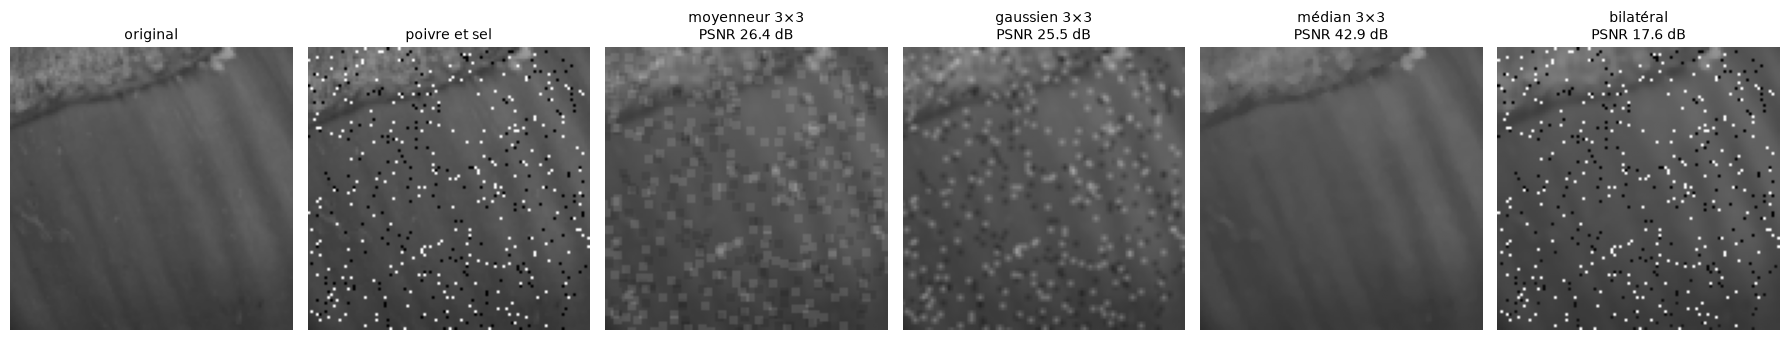

In [3]:
c = "hazelnut"; im = G[c]["val"][0]; sp = salt_pepper(im)
crop = (slice(70, 170), slice(70, 170))
fig, axes = plt.subplots(1, 6, figsize=(18, 3.4))
show = [("original", im), ("poivre et sel", sp)] + [(f, denoise(sp, *FILTERS[f])) for f in ["moyenneur 3×3", "gaussien 3×3", "médian 3×3", "bilatéral"]]
for ax, (t, x) in zip(axes, show):
    ax.imshow(x[crop], cmap="gray", vmin=0, vmax=255); ax.axis("off")
    ax.set_title(t if t in ("original", "poivre et sel") else f"{t}\nPSNR {psnr(im, x, data_range=255):.1f} dB", fontsize=10)
plt.tight_layout(); plt.savefig(OUT / "A_filtres_exemple.png", dpi=120); plt.show()

## B. Normalisation photométrique
Rappel du notebook 01 : le fond des images de **test** est plus clair que celui des images d'**apprentissage** (hazelnut : 30 → 37). On applique chaque méthode (après le filtre médian 3×3), puis on mesure la distance de Bhattacharyya entre l'histogramme de chaque image et l'histogramme moyen d'apprentissage :
- **rapport de décalage** = distance moyenne *test sain* / distance moyenne *validation* → **idéalement ≈ 1** (pas de décalage d'acquisition) ;
- **AUROC histogramme global** : ne doit plus être *inversée* (< 0,5).

In [4]:
NORMS = ["none", "equalize", "clahe", "zscore", "minmax"]
def h64(im):
    v = cv2.calcHist([im], [0], None, [64], [0, 256]).ravel(); return (v / v.sum()).astype(np.float32)
rows = []
for c in CATS:
    med = {k: [denoise(im, "median", 3) for im in v] for k, v in G[c].items()}
    for nm in NORMS:
        N = {k: [normalize_photometric(im, nm) for im in v] for k, v in med.items()}
        ref = np.mean([h64(im) for im in N["train"]], 0).astype(np.float32)
        d = lambda L: np.array([cv2.compareHist(ref, h64(im), cv2.HISTCMP_BHATTACHARYYA) for im in L])
        dv, dt = d(N["val"]), d(N["test"])
        rows.append({"catégorie": c, "normalisation": nm, "dist. validation": dv.mean(),
                     "dist. test sain": dt[Y[c] == 0].mean(), "dist. test défaut": dt[Y[c] == 1].mean(),
                     "rapport décalage (≈1 idéal)": dt[Y[c] == 0].mean() / dv.mean(),
                     "AUROC hist. global": roc_auc_score(Y[c], dt)})
df_n = pd.DataFrame(rows).set_index(["catégorie", "normalisation"]).round(3)
df_n.to_csv(OUT / "B_normalisation.csv"); df_n

dist. validation  dist. test sain  dist. test défaut  \
catégorie normalisation                                                         
bottle    none                      0.062            0.094              0.110   
          equalize                  0.174            0.163              0.162   
          clahe                     0.039            0.041              0.065   
          zscore                    0.095            0.075              0.101   
          minmax                    0.053            0.063              0.082   
hazelnut  none                      0.241            0.541              0.354   
          equalize                  0.602            0.600              0.597   
          clahe                     0.133            0.295              0.195   
          zscore                    0.216            0.194              0.238   
          minmax                    0.196            0.187              0.233   
carpet    none                      0.045            0.072              0.045   
          equalize                  0.150            0.156              0.155   
          clahe                     0.026            0.031              0.026   
          zscore                    0.076            0.075              0.076   
          minmax                    0.114            0.114              0.116   

                         rapport décalage (≈1 idéal)  AUROC hist. global  
catégorie normalisation                                                   
bottle    none                                 1.519               0.522  
          equalize                             0.935               0.528  
          clahe                                1.049               0.747  
          zscore                               0.790               0.651  
          minmax                               1.173               0.612  
hazelnut  none                                 2.245               0.001  
          equalize                             0.997               0.481  
          clahe                                2.225               0.024  
          zscore                               0.895               0.582  
          minmax                               0.955               0.591  
carpet    none                                 1.605               0.200  
          equalize                             1.039               0.507  
          clahe                                1.182               0.222  
          zscore                               0.988               0.542  
          minmax                               1.002               0.571

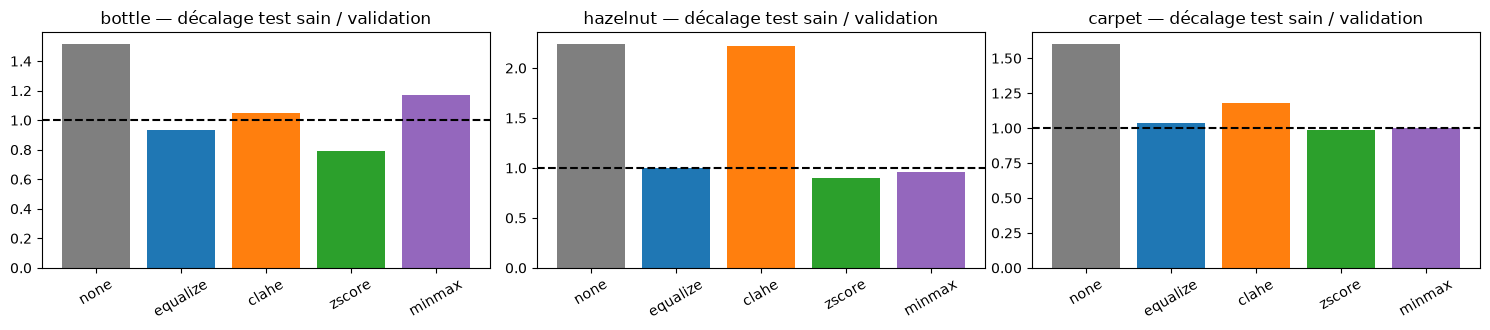

In [5]:
fig, axes = plt.subplots(1, len(CATS), figsize=(5 * len(CATS), 3.4))
for ax, c in zip(axes, CATS):
    sub = df_n.loc[c]
    ax.bar(sub.index, sub["rapport décalage (≈1 idéal)"], color=["tab:gray", "tab:blue", "tab:orange", "tab:green", "tab:purple"])
    ax.axhline(1, color="k", ls="--"); ax.set_title(f"{c} — décalage test sain / validation"); ax.tick_params(axis="x", rotation=30)
plt.tight_layout(); plt.savefig(OUT / "B_normalisation.png", dpi=120); plt.show()

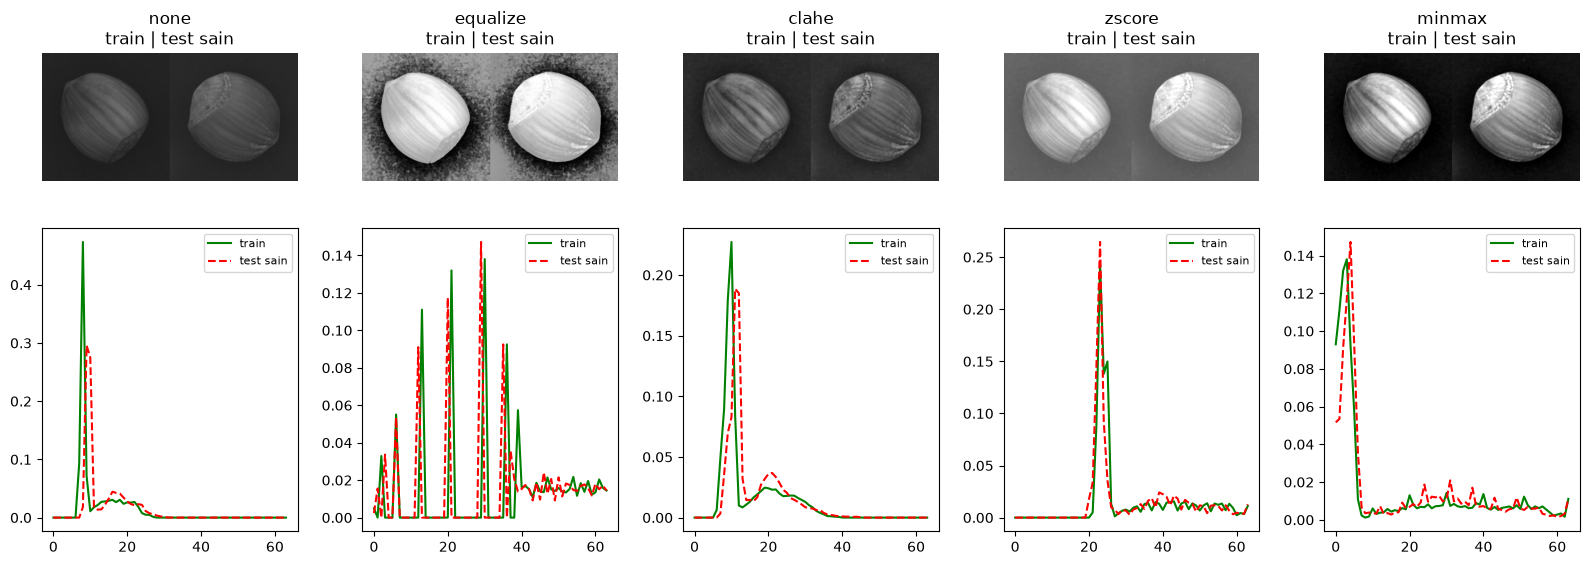

In [6]:
c = "hazelnut"
tr = denoise(G[c]["train"][0], "median", 3); te = denoise(G[c]["test"][np.where(Y[c] == 0)[0][0]], "median", 3)
fig, axes = plt.subplots(2, len(NORMS), figsize=(3.2 * len(NORMS), 6.2))
for j, nm in enumerate(NORMS):
    a, b = normalize_photometric(tr, nm), normalize_photometric(te, nm)
    axes[0, j].imshow(np.hstack([a, b]), cmap="gray", vmin=0, vmax=255); axes[0, j].axis("off"); axes[0, j].set_title(f"{nm}\ntrain | test sain")
    axes[1, j].plot(h64(a), "g", label="train"); axes[1, j].plot(h64(b), "r--", label="test sain"); axes[1, j].legend(fontsize=8)
plt.tight_layout(); plt.savefig(OUT / "B_normalisation_exemple.png", dpi=120); plt.show()

## C. Alignement spatial (objets : bottle, hazelnut)
Méthodes comparées (référence = médiane des images d'apprentissage alignées, 2 itérations) :
- **orb** : points ORB → appariement Hamming + test de ratio → RANSAC (`estimateAffinePartial2D`) → `warpAffine` bilinéaire ;
- **rotsearch** : centroïde de la région Otsu ramené au centre (translation), puis recherche de l'angle de rotation maximisant la corrélation normalisée (NCC) avec la référence ;
- **orb+rotsearch** : ORB, et repli sur rotsearch quand ORB échoue.

Mesures : NCC moyenne avec la référence (validation et test sain), taux de recours à chaque méthode, écart-type pixel à pixel des images alignées (plus il est faible, plus l'alignement est bon).

In [7]:
NORM = "minmax"   # retenu à l'expérience B (voir conclusions)
def base(im): return normalize_photometric(denoise(im, "median", 3), NORM)
METHODS = ["none", "orb", "rotsearch", "orb+rotsearch"]
OBJ = [c for c in CATS if c not in cfg["preprocessing"]["no_align_categories"]]
rows, aligned_store, refs = [], {}, {}
for c in OBJ:
    tr = [base(im) for im in G[c]["train"]]; va = [base(im) for im in G[c]["val"]]
    tg = [base(im) for im, y in zip(G[c]["test"], Y[c]) if y == 0]
    for m in METHODS:
        t0 = time.time(); al = Aligner(method=m); al.fit(tr); t_fit = time.time() - t0
        t0 = time.time(); res_v = [al.transform(im) for im in va]; t_one = (time.time() - t0) / len(va)
        res_t = [al.transform(im) for im in tg]
        stack = np.stack([r[0] for r in res_v]).astype(np.float32)
        used = pd.Series([r[1].method for r in res_v + res_t]).value_counts(normalize=True)
        rows.append({"catégorie": c, "méthode": m, "NCC val": np.mean([r[1].ncc for r in res_v]),
                     "NCC test sain": np.mean([r[1].ncc for r in res_t]), "écart-type moyen (val)": stack.std(0).mean(),
                     "part ORB réussi": used.get("orb", 0.0), "part rotsearch": used.get("rotsearch", 0.0),
                     "temps / image (ms)": 1000 * t_one, "construction réf. (s)": t_fit})
        aligned_store[(c, m)] = stack; refs[(c, m)] = al.reference
df_a = pd.DataFrame(rows).set_index(["catégorie", "méthode"]).round(3)
df_a.to_csv(OUT / "C_alignement.csv"); df_a

NCC val  NCC test sain  écart-type moyen (val)  \
catégorie méthode                                                         
bottle    none             0.994          0.994                7.582000   
          orb              0.994          0.994                7.415000   
          rotsearch        0.996          0.995                6.236000   
          orb+rotsearch    0.996          0.995                6.226000   
hazelnut  none             0.913          0.930               21.945000   
          orb              0.913          0.930               21.945000   
          rotsearch        0.927          0.946               20.983000   
          orb+rotsearch    0.927          0.946               20.978001   

                         part ORB réussi  part rotsearch  temps / image (ms)  \
catégorie méthode                                                              
bottle    none                     0.000           0.000               0.000   
          orb                      0.210           0.000               5.230   
          rotsearch                0.000           1.000              12.969   
          orb+rotsearch            0.677           0.323              13.684   
hazelnut  none                     0.000           0.000               0.172   
          orb                      0.000           0.000               3.345   
          rotsearch                0.000           1.000              32.677   
          orb+rotsearch            0.000           1.000              37.020   

                         construction réf. (s)  
catégorie méthode                               
bottle    none                           0.113  
          orb                            4.258  
          rotsearch                      5.058  
          orb+rotsearch                  5.816  
hazelnut  none                           0.232  
          orb                            5.359  
          rotsearch                     18.285  
          orb+rotsearch                 22.813

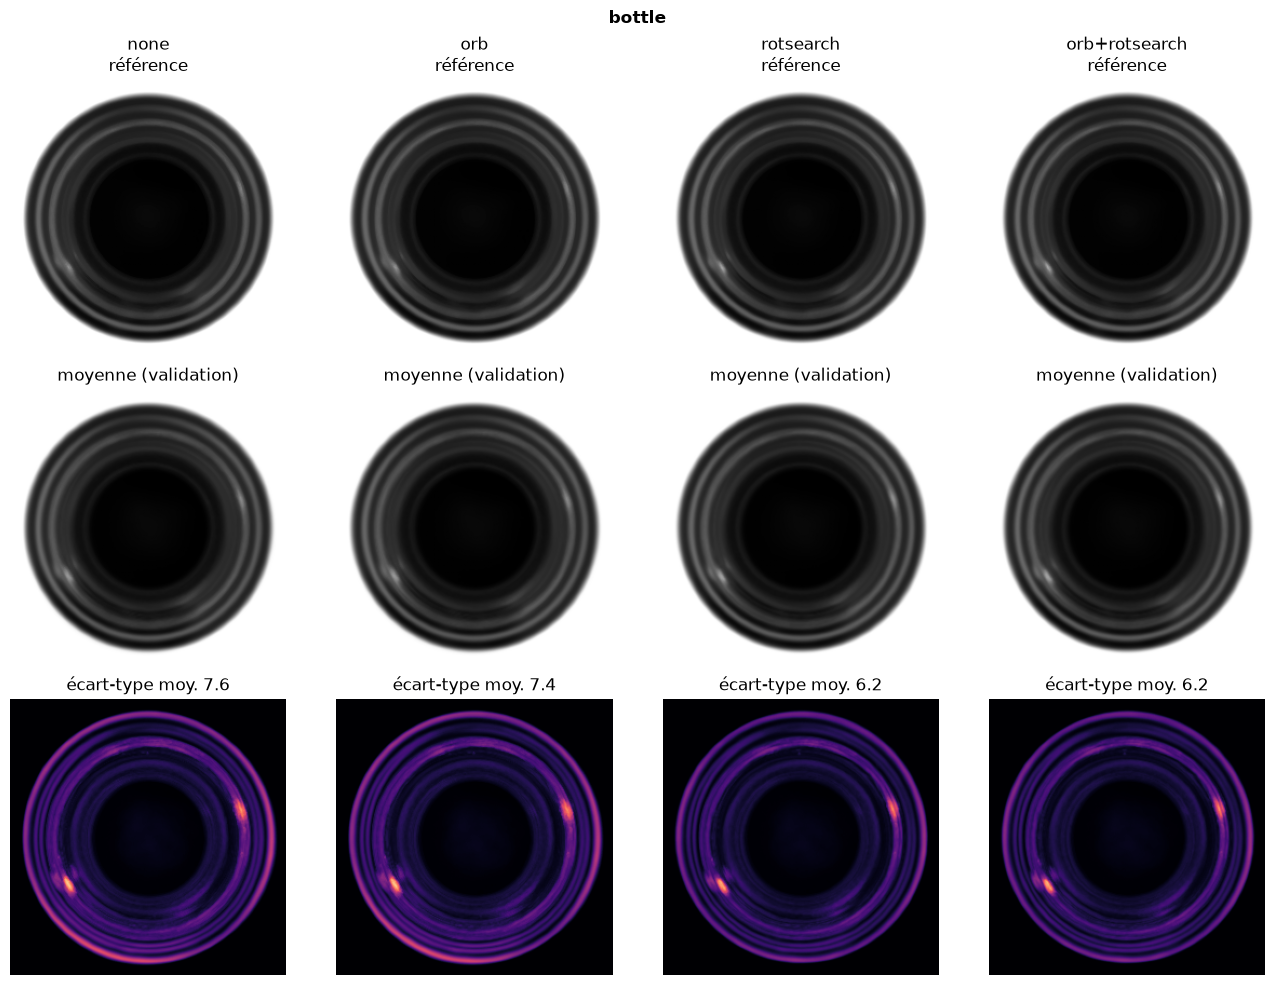

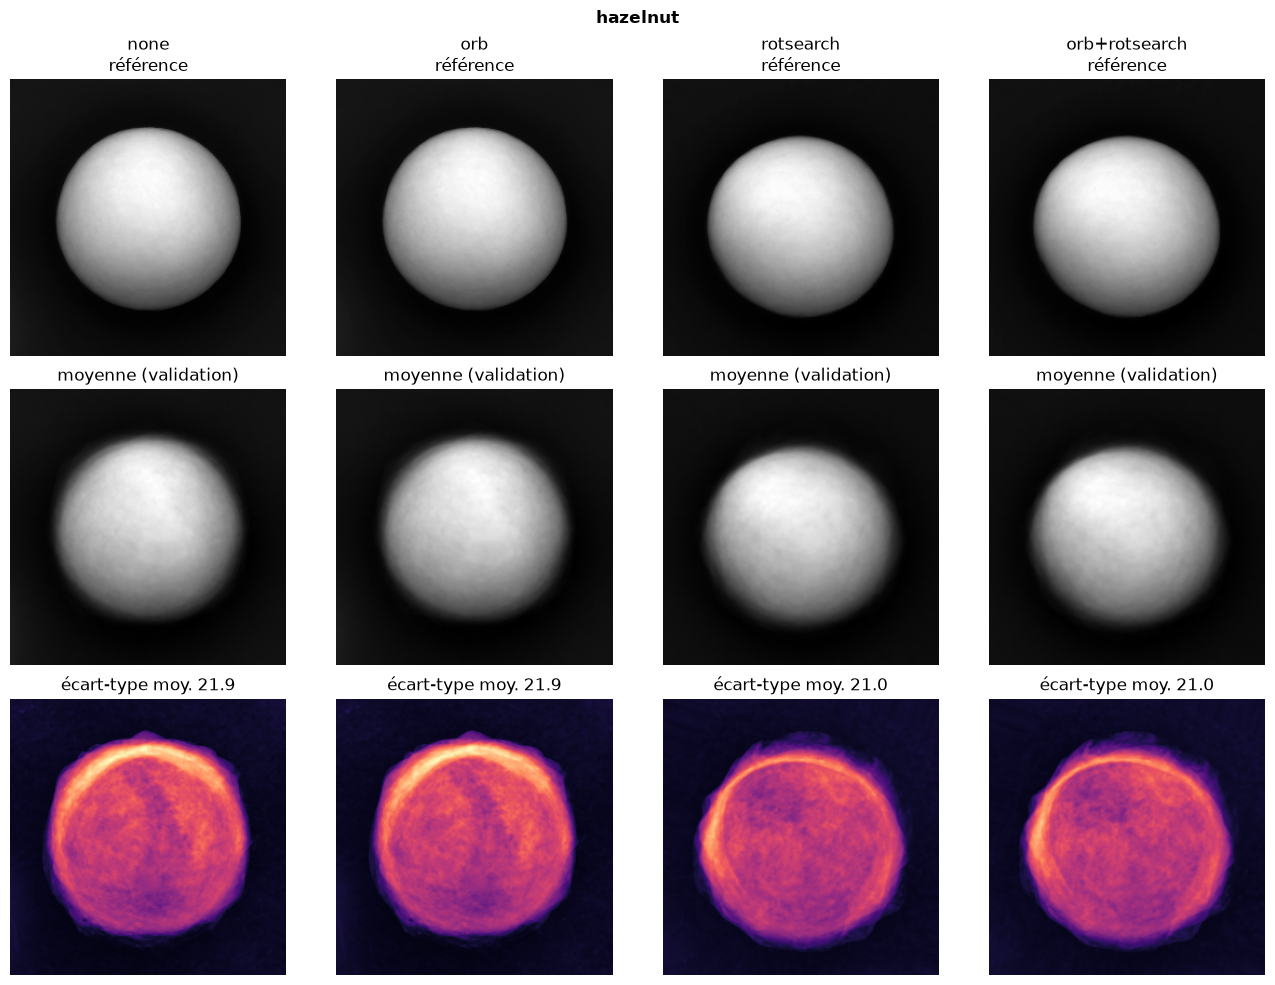

In [8]:
for c in OBJ:
    fig, axes = plt.subplots(3, len(METHODS), figsize=(3.3 * len(METHODS), 10))
    for j, m in enumerate(METHODS):
        st = aligned_store[(c, m)]
        axes[0, j].imshow(refs[(c, m)], cmap="gray"); axes[0, j].set_title(f"{m}\nréférence")
        axes[1, j].imshow(st.mean(0), cmap="gray"); axes[1, j].set_title("moyenne (validation)")
        axes[2, j].imshow(st.std(0), cmap="magma", vmin=0, vmax=80); axes[2, j].set_title(f"écart-type moy. {st.std(0).mean():.1f}")
        for a in axes[:, j]: a.axis("off")
    fig.suptitle(c, fontweight="bold"); plt.tight_layout(); plt.savefig(OUT / f"C_alignement_{c}.png", dpi=110); plt.show()

## D. Chaîne complète sur des exemples de test (avec masque recalé)
On applique la configuration retenue (`Preprocessor`), y compris au **masque vérité terrain**, qui doit subir exactement la même transformation géométrique (interpolation *plus proche voisin* pour rester binaire, Ch. 2).

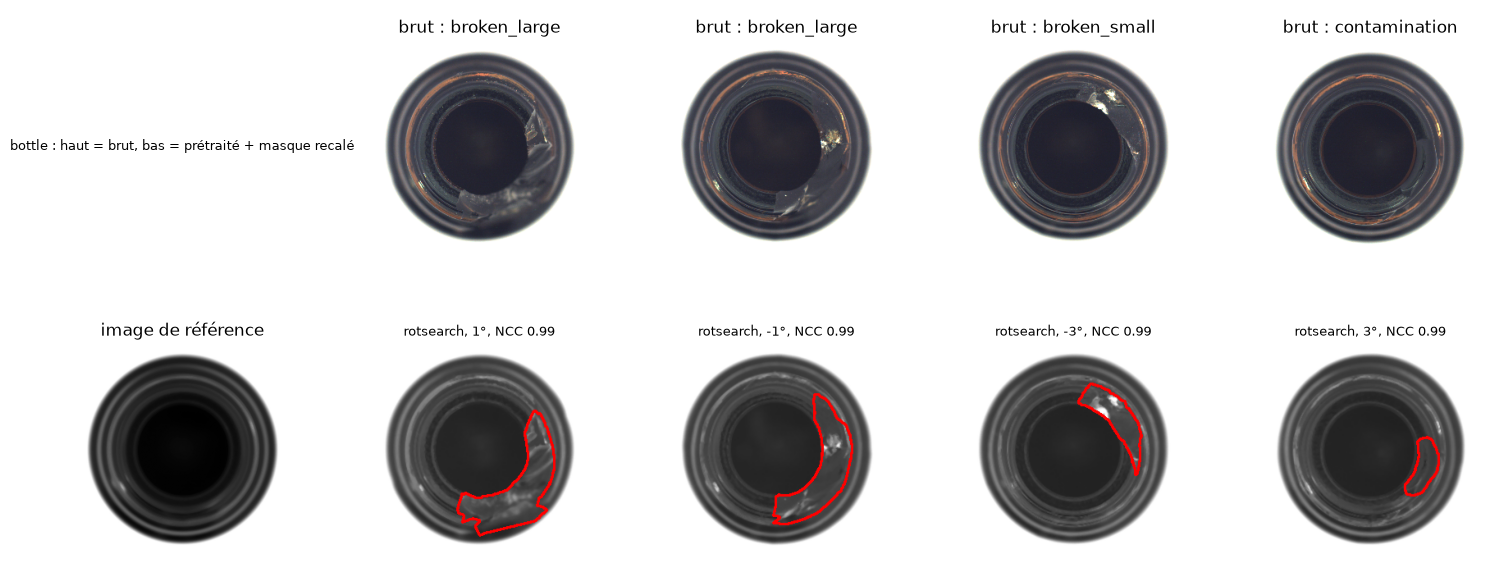

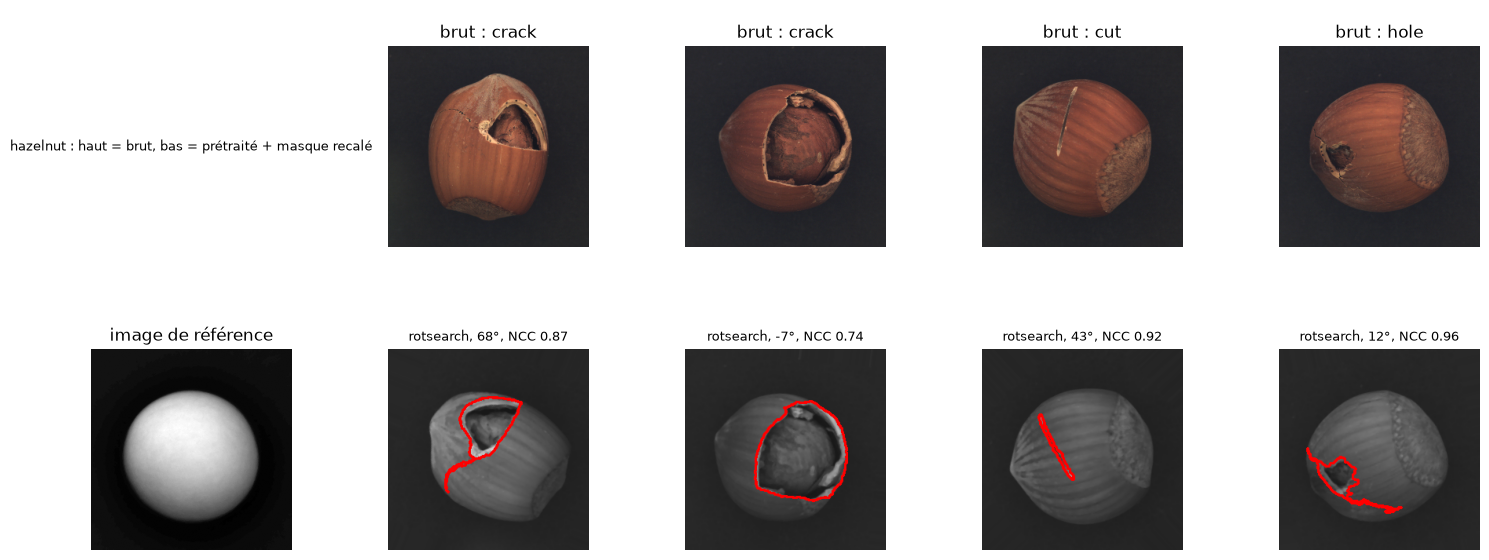

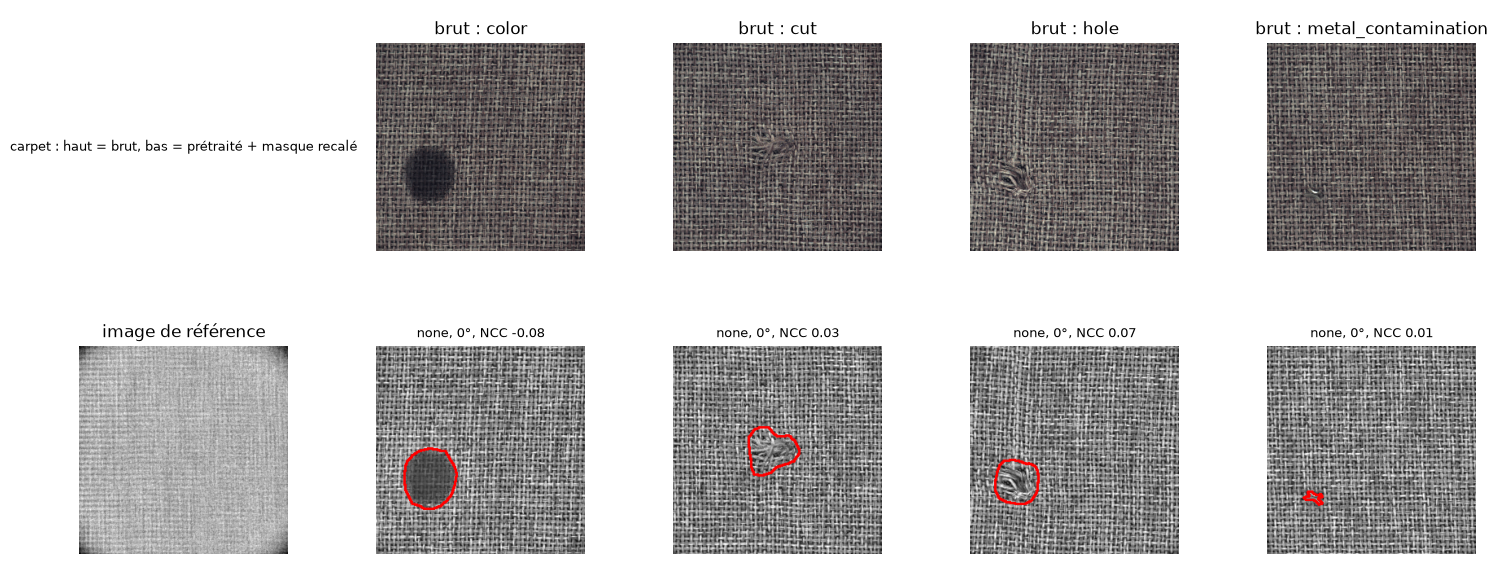

In [9]:
def overlay(gray, mask):
    rgb = cv2.cvtColor(gray, cv2.COLOR_GRAY2RGB)
    cnts, _ = cv2.findContours(mask.astype(np.uint8), cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    cv2.drawContours(rgb, cnts, -1, (255, 0, 0), 2); return rgb
pre = {}
for c in CATS:
    p = Preprocessor.from_config(cfg, c)   # configuration retenue (config.yaml)
    p.fit([load_image(x.path) for x in splits[c]["train"]]); pre[c] = p
    test = splits[c]["test"]; picks = [x for x in test if x.label][::max(1, sum(Y[c]) // 4)][:4]
    fig, axes = plt.subplots(2, len(picks) + 1, figsize=(3 * (len(picks) + 1), 6.2))
    axes[0, 0].text(0.5, 0.5, c + " : haut = brut, bas = prétraité + masque recalé", ha="center", va="center", fontsize=9, wrap=True)
    axes[1, 0].imshow(p.reference, cmap="gray"); axes[1, 0].set_title("image de référence")
    for j, x in enumerate(picks, 1):
        raw = load_image(x.path); out, m, info = p.transform_with_mask(raw, load_mask(x))
        axes[0, j].imshow(cv2.cvtColor(cv2.resize(raw, (S, S)), cv2.COLOR_BGR2RGB)); axes[0, j].set_title(f"brut : {x.defect}")
        axes[1, j].imshow(overlay(out, m)); axes[1, j].set_title(f"{info.method}, {info.angle:.0f}°, NCC {info.ncc:.2f}", fontsize=9)
    for a in axes.ravel(): a.axis("off")
    plt.tight_layout(); plt.savefig(OUT / f"D_chaine_{c}.png", dpi=110); plt.show()

## Conclusions — configuration retenue (écrite dans `config.yaml`)

**A. Filtre : médian 3×3.**
- Sur le bruit poivre et sel, c'est de loin le meilleur filtre : **34,8 dB / SSIM 0,91**, contre 24,7 dB pour le moyenneur et 17,7 dB pour le bilatéral, qui laisse passer les impulsions. Cela confirme le Ch. 3.
- Sur le bruit gaussien, il est légèrement moins bon que le gaussien ou le bilatéral (28,8 dB contre environ 29,5 dB).
- Appliqué à une image **propre**, il conserve bien les détails (SSIM 0,92), alors qu'un médian 5×5 en détruit trop (SSIM 0,74). C'est important, car les petits défauts sont des détails fins.
- Les images MVTec sont peu bruitées : le médian 3×3 sert ici de protection contre les pixels aberrants, sans abîmer l'image.

**B. Normalisation : étirement linéaire `minmax` (centiles 1-99 ramenés sur [0, 255]).**
- Le décalage d'éclairage entre l'apprentissage et le test disparaît : rapport de 2,25 → **0,96** pour hazelnut et de 1,61 → **1,00** pour carpet.
- L'AUROC de l'histogramme global n'est plus inversée (hazelnut : 0,00 → 0,59).
- `zscore` donne un résultat proche. `equalize` aligne aussi les distributions, mais **efface l'information d'intensité** : toutes les distances deviennent identiques, même pour les défauts. `clahe` **ne corrige pas** le décalage (hazelnut : 2,23).

**C. Alignement : `rotsearch` (centrage sur le centroïde de la région, puis recherche de l'angle par corrélation).**
- **ORB et RANSAC sont peu fiables entre deux objets différents.** Seuls **21 % des recalages réussissent pour bottle et 0 % pour hazelnut**. Pourtant, ORB retrouve une rotation connue de 40° sur la *même* image avec 253 inliers. La raison : deux noix (ou deux bouteilles) différentes n'ont **pas les mêmes points caractéristiques**. ORB recale un même objet vu deux fois, pas deux individus différents.
- `rotsearch` donne le meilleur alignement : écart-type pixel à pixel de bottle 7,6 → **6,2** (−18 %) ; NCC de hazelnut 0,91 → 0,93. Le masque vérité terrain suit bien la transformation (figures D).
- **Limite pour hazelnut :** l'image de référence est un disque presque rond. Comme chaque noix a sa propre forme et sa propre texture, l'angle est mal déterminé et le gain reste modeste (écart-type 21,9 → 21,0, soit −4 %). **Conséquence pour la suite :** pour hazelnut, il faudra des caractéristiques de zone **peu sensibles à la position exacte** (histogrammes, statistiques) et un **modèle partagé entre les zones** plutôt qu'un modèle par position. Ce choix sera comparé dans l'ablation.
- Les descripteurs ORB et SIFT restent utilisés à l'étape 5 comme **caractéristiques** (sac de mots visuels), ce qui est leur rôle dans le sujet.

**Mise à jour (étape 6) : normalisation propre aux textures.** Pour carpet, les images de test présentent un **éclairage non uniforme** : un dégradé gauche-droite de +13,8 niveaux, contre +5,2 pour les images saines. Ce diagnostic a été fait **sans étiquettes**. Une normalisation globale (`minmax`) ne peut pas le corriger. Carpet utilise donc `localnorm` : l'éclairage, estimé par un flou gaussien large (filtre passe-bas, Ch. 3), est soustrait, puis on divise par le contraste local. Le dégradé tombe à +2,8. Les objets (bottle, hazelnut) gardent `minmax`, car leur fond et leur objet ont réellement des intensités différentes. Les figures D ci-dessus utilisent cette configuration finale.

**Mise à jour (étape 8) : configuration finale et biais corrigé.**
- *Biais signalé :* le choix de `minmax` ci-dessus (partie B) s'appuie sur une mesure qui compare les images **saines du test** à la validation. Cela revient à utiliser un peu les étiquettes du test pour choisir le prétraitement.
- *Correction :* à l'étape 8, le prétraitement de chaque catégorie a été **choisi à nouveau par le critère sans étiquettes** (anomalies synthétiques, notes hors-pli) parmi les variantes de l'étude d'ablation.
  - **bottle** et **hazelnut** : **sans normalisation** (critère 0,996 et 0,833, contre 0,980 et 0,795 avec `minmax`). Leur fond uniforme et le modèle par zone supportent les écarts d'éclairage. Pour hazelnut, la normalisation `minmax` (étirement des centiles 1-99) déformait même les intensités de la noix selon la quantité de fond visible.
  - **carpet** : **normalisation locale** conservée (critère 0,900, contre 0,892 sans normalisation) et **sans filtre médian** (critère 0,917, contre 0,900 avec le médian).
- Les figures D ci-dessus utilisent cette configuration finale.